# Classificação de ocorrências de roubo e furto de celulares — São Paulo (2025)

Notebook autocontido para Google Colab. Ele lê a base oficial `CelularesSubtraidos_2025.xlsx`, seleciona ocorrências cujo **local do fato** é o município de São Paulo (`CIDADE`), trata duplicidades conforme a metodologia da SSP-SP e compara três arquiteturas de MLP.

**Importante:** a base é de celulares subtraídos e tem caráter exploratório. O modelo classifica registros de ocorrências já registradas; não prevê onde ou quando crimes acontecerão. A deduplicação usa `NOME_DELEGACIA + ANO_BO + NUM_BO`; boletins com rótulos conflitantes são excluídos.

Execute as células em ordem. Na primeira execução, envie o Excel quando solicitado.

In [12]:
!pip -q install openpyxl scikit-learn pandas matplotlib seaborn joblib

## 1. Carregar a base

In [13]:
from google.colab import files
import os, glob, warnings
import pandas as pd
import numpy as np

# Se o Excel já estiver em /content, usa-o; caso contrário, abre o seletor de upload.
possiveis = glob.glob('/content/*.xlsx')
if not possiveis:
    print('Envie CelularesSubtraidos_2025.xlsx')
    enviados = files.upload()
    possiveis = [('/content/' + nome) for nome in enviados if nome.lower().endswith('.xlsx')]
if not possiveis:
    raise FileNotFoundError('Não encontrei um arquivo .xlsx. Envie a planilha original da SSP-SP.')
ARQUIVO = possiveis[0]
print('Arquivo:', ARQUIVO)
df = pd.read_excel(ARQUIVO, sheet_name='CELULAR_2025', dtype=str, engine='openpyxl')
print('Dimensão bruta:', df.shape)
display(df.head())

Arquivo: /content/CelularesSubtraidos_2025.xlsx
Dimensão bruta: (383635, 55)


,ID_DELEGACIA,NOME_DEPARTAMENTO,NOME_SECCIONAL,NOME_DELEGACIA,NOME_MUNICIPIO,ANO_BO,NUM_BO,VERSAO,NOME_DEPARTAMENTO_CIRC,NOME_SECCIONAL_CIRC,...,QUANTIDADE_OBJETO,MARCA_OBJETO,FLAG_BLOQUEIO,FLAG_DESBLOQUEIO,MES_REGISTRO_BO,ANO_REGISTRO_BO,CMD,BTL,CIA,CD_IBGE
0,900020,DIPOL - DEPTO DE INTELIGENCIA,DELEGACIA ELETRONICA,DELEGACIA ELETRONICA,S.PAULO,2025,AA1691,1,DECAP,DEL.SEC.1º CENTRO,...,1,Xiaomi,S,N,1,2025,CPA/M-1,7ºBPM/M,3ªCIA_4ªCIA,3550308
1,900021,DIPOL - DEPTO DE INTELIGENCIA,DELEGACIA ELETRONICA,DELEGACIA ELETRONICA 1,S.PAULO,2025,AA2064,1,DECAP,DEL.SEC.1º CENTRO,...,1,Apple,S,N,1,2025,CPA/M-1,7ºBPM/M,3ªCIA_4ªCIA,3550308
2,900020,DIPOL - DEPTO DE INTELIGENCIA,DELEGACIA ELETRONICA,DELEGACIA ELETRONICA,S.PAULO,2025,AA2458,1,DECAP,DEL.SEC.1º CENTRO,...,1,Motorola,S,N,1,2025,CPA/M-1,7ºBPM/M,3ªCIA_4ªCIA,3550308
3,900020,DIPOL - DEPTO DE INTELIGENCIA,DELEGACIA ELETRONICA,DELEGACIA ELETRONICA,S.PAULO,2025,AA2520,1,DECAP,DEL.SEC.1º CENTRO,...,1,Samsung,S,N,1,2025,CPA/M-1,7ºBPM/M,3ªCIA_4ªCIA,3550308
4,900020,DIPOL - DEPTO DE INTELIGENCIA,DELEGACIA ELETRONICA,DELEGACIA ELETRONICA,S.PAULO,2025,AA2537,1,DECAP,DEL.SEC.1º CENTRO,...,1,Apple,S,N,1,2025,CPA/M-1,7ºBPM/M,3ªCIA_4ªCIA,3550308


Foi utilizada a base Celulares Subtraídos – SSP-SP (2025), disponibilizada pela Secretaria de Segurança Pública de São Paulo. O arquivo contém registros de ocorrências relacionados à subtração de celulares e foi carregado com Pandas para permitir a análise e o tratamento dos dados.

## 2. Seleção e limpeza dos dados

`CIDADE` representa a cidade dos fatos. Não usar `NOME_MUNICIPIO`, pois esse campo identifica o município da delegacia responsável pelo registro.

In [14]:
# Normalização de texto e valores nulos
for col in df.columns:
    if df[col].dtype == 'object':
        df[col] = df[col].astype('string').str.strip()
        df[col] = df[col].replace({'NULL': pd.NA, 'null': pd.NA, '': pd.NA, 'nan': pd.NA})

# Filtro pelo município onde ocorreu o fato
cidade = df['CIDADE'].fillna('').str.upper().str.normalize('NFKD').str.encode('ascii', errors='ignore').str.decode('ascii')
df = df[cidade.isin(['S.PAULO', 'SAO PAULO'])].copy()

# Rótulo binário a partir da natureza criminal
rubrica = df['RUBRICA'].fillna('').str.upper()
df['ALVO'] = np.select(
    [rubrica.str.contains(r'ROUBO\s*\(ART\.\s*157', regex=True),
     rubrica.str.contains(r'FURTO\s*\(ART\.\s*155', regex=True)],
    ['Roubo', 'Furto'], default=pd.NA
)
df = df[df['ALVO'].notna()].copy()
print('Após filtro cidade e natureza:', df.shape)
print(df['ALVO'].value_counts())
print('Cidades dos fatos:', df['CIDADE'].value_counts().head())

Após filtro cidade e natureza: (183798, 56)
ALVO
Furto    106392
Roubo     77406
Name: count, dtype: int64
Cidades dos fatos: CIDADE
S.PAULO    183798
Name: count, dtype: Int64


Nesta etapa, foram selecionados apenas os registros da cidade de São Paulo, considerando as ocorrências classificadas como roubo ou furto. Essa filtragem garante que os dados estejam alinhados ao objetivo do projeto, que é realizar a classificação entre essas duas categorias.

## 3. Deduplicação por boletim e criação das variáveis

In [15]:
# A metodologia da SSP-SP indica NOME_DELEGACIA + ANO_BO + NUM_BO como chave da ocorrência.
chave = ['NOME_DELEGACIA', 'ANO_BO', 'NUM_BO']
# Remover registros sem chave completa
df = df.dropna(subset=chave).copy()
# Excluir boletins em que aparecem simultaneamente rótulos Roubo e Furto
rotulos_por_bo = df.groupby(chave)['ALVO'].nunique()
chaves_validas = rotulos_por_bo[rotulos_por_bo == 1].index
df = df.set_index(chave).loc[df.set_index(chave).index.isin(chaves_validas)].reset_index()
# Uma linha por boletim
df = df.drop_duplicates(subset=chave, keep='first').copy()

# Data/hora do fato
df['DATA_OCORRENCIA_BO'] = pd.to_datetime(df['DATA_OCORRENCIA_BO'], errors='coerce', dayfirst=True)
df['HORA_OCORRENCIA'] = df['HORA_OCORRENCIA'].astype('string').replace('<NA>', pd.NA)
df['MES'] = df['DATA_OCORRENCIA_BO'].dt.month
df['DIA_SEMANA'] = df['DATA_OCORRENCIA_BO'].dt.dayofweek
df['HORA'] = pd.to_datetime(df['HORA_OCORRENCIA'], format='%H:%M:%S', errors='coerce').dt.hour
# Algumas planilhas podem armazenar hora como HH:MM
mask = df['HORA'].isna()
df.loc[mask, 'HORA'] = pd.to_datetime(df.loc[mask, 'HORA_OCORRENCIA'], format='%H:%M', errors='coerce').dt.hour

# Variáveis de entrada disponíveis na base; sem identificadores do boletim ou campos posteriores ao fato
features_cat = ['BAIRRO', 'DESCR_TIPOLOCAL', 'DESCR_SUBTIPOLOCAL', 'DESCR_PERIODO']
features_num = ['MES', 'DIA_SEMANA', 'HORA']
for col in features_cat:
    if col not in df.columns: df[col] = pd.NA
for col in features_num:
    if col not in df.columns: df[col] = np.nan

base = df[features_cat + features_num + ['ALVO']].copy()
base = base.dropna(subset=['ALVO'])
# Remover categorias vazias para o pré-processador tratar como categoria ausente
for col in features_cat:
    base[col] = base[col].fillna('Não informado').astype(str)
for col in features_num:
    base[col] = pd.to_numeric(base[col], errors='coerce')
base = base.drop_duplicates().reset_index(drop=True)
print('Base final:', base.shape)
display(base.head())
print(base['ALVO'].value_counts())
# Salvar CSV tratado para reutilização/download
csv_path = '/content/base_roubo_furto_sp_2025.csv'
base.to_csv(csv_path, index=False, encoding='utf-8-sig')
print('CSV salvo em:', csv_path)

/tmp/ipykernel_2954/4041773966.py:13: UserWarning: Parsing dates in %Y-%m-%d %H:%M:%S format when dayfirst=True was specified. Pass `dayfirst=False` or specify a format to silence this warning.
  df['DATA_OCORRENCIA_BO'] = pd.to_datetime(df['DATA_OCORRENCIA_BO'], errors='coerce', dayfirst=True)


Base final: (115031, 8)


,BAIRRO,DESCR_TIPOLOCAL,DESCR_SUBTIPOLOCAL,DESCR_PERIODO,MES,DIA_SEMANA,HORA,ALVO
0,LIBERDADE,Via Pública,Via Pública,Não informado,12,1,18.0,Roubo
1,SE,Via Pública,Via Pública,Não informado,12,0,15.0,Furto
2,BELA VISTA,Via Pública,Via Pública,Não informado,1,2,4.0,Roubo
3,LIBERDADE,Via Pública,Via Pública,De madrugada,1,2,NaN,Furto
4,LIBERDADE,Terminal/Estação,Metroviário e Ferroviário Metropolitano,A noite,12,6,NaN,Furto


ALVO
Furto    64301
Roubo    50730
Name: count, dtype: int64
CSV salvo em: /content/base_roubo_furto_sp_2025.csv


Foram removidos registros duplicados para evitar que uma mesma ocorrência fosse considerada mais de uma vez. Em seguida, foram selecionadas as variáveis utilizadas na classificação, como informações de localização e período da ocorrência. Após o tratamento, a base ficou com 115.031 registros.

## 4. Análise exploratória

Registros: 115031
Valores ausentes por coluna:


,ausentes
BAIRRO,0
DESCR_TIPOLOCAL,0
DESCR_SUBTIPOLOCAL,0
DESCR_PERIODO,0
MES,0
DIA_SEMANA,0
HORA,46693
ALVO,0


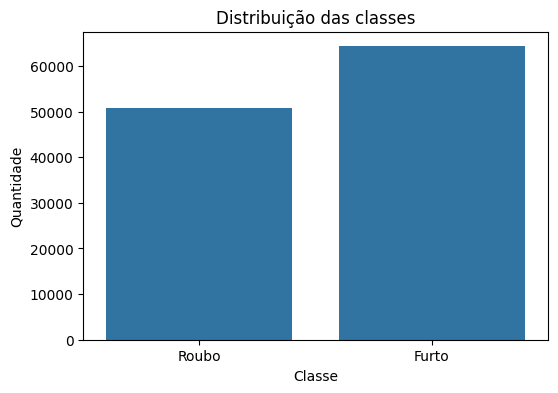

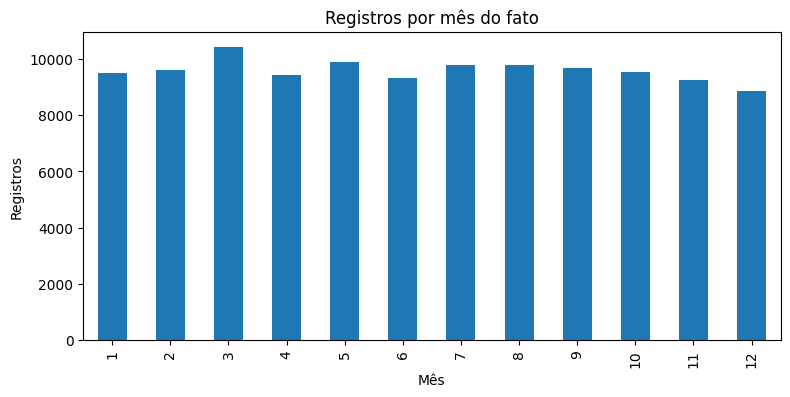

In [16]:
import matplotlib.pyplot as plt
import seaborn as sns

print('Registros:', len(base))
print('Valores ausentes por coluna:')
display(base.isna().sum().to_frame('ausentes'))
plt.figure(figsize=(6,4))
sns.countplot(data=base, x='ALVO')
plt.title('Distribuição das classes')
plt.xlabel('Classe'); plt.ylabel('Quantidade'); plt.show()

plt.figure(figsize=(9,4))
base.groupby('MES', dropna=False)['ALVO'].count().plot(kind='bar')
plt.title('Registros por mês do fato'); plt.xlabel('Mês'); plt.ylabel('Registros'); plt.show()

A análise mostrou uma quantidade maior de registros de furto em comparação com roubo. Também foram observadas a distribuição mensal das ocorrências e a presença de valores ausentes, principalmente na variável de horário. Essas informações ajudam a compreender as características e limitações da base antes do treinamento.

## 5. Separação treino, validação e teste e pré-processamento

In [17]:
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler, LabelEncoder
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.neural_network import MLPClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             confusion_matrix, classification_report)

X = base[features_cat + features_num].copy()
y = (base['ALVO'] == 'Roubo').astype(int) # 1=Roubo; 0=Furto
X_train, X_temp, y_train, y_temp = train_test_split(X, y, test_size=0.30, random_state=42, stratify=y)
X_val, X_test, y_val, y_test = train_test_split(X_temp, y_temp, test_size=0.50, random_state=42, stratify=y_temp)

preprocessador = ColumnTransformer(transformers=[
    ('cat', Pipeline([('imputer', SimpleImputer(strategy='constant', fill_value='Não informado')),
                      ('onehot', OneHotEncoder(handle_unknown='ignore'))]), features_cat),
    ('num', Pipeline([('imputer', SimpleImputer(strategy='median')), ('scaler', StandardScaler())]), features_num)
])
print('Treino:', X_train.shape, 'Validação:', X_val.shape, 'Teste:', X_test.shape)

Treino: (80521, 7) Validação: (17255, 7) Teste: (17255, 7)


Os dados foram divididos em três conjuntos: treinamento, validação e teste. O treinamento foi utilizado para ensinar o modelo, a validação para comparar as arquiteturas e o teste para avaliar o desempenho final. As variáveis categóricas foram codificadas e as numéricas foram padronizadas para serem utilizadas pela rede neural.

## 6. Treinar e comparar três arquiteturas MLP

A escolha do melhor modelo usa o F1 da validação. O conjunto de teste fica reservado para a avaliação final.

In [18]:
arquiteturas = {
    'MLP_1_camada_32': (32,),
    'MLP_2_camadas_64_32': (64, 32),
    'MLP_3_camadas_128_64_32': (128, 64, 32),
}
resultados = []
modelos = {}
historicos = {}

for nome, camadas in arquiteturas.items():
    modelo = Pipeline([
        ('prep', preprocessador),
        ('mlp', MLPClassifier(hidden_layer_sizes=camadas, activation='relu', solver='adam',
                              alpha=0.001, learning_rate_init=0.001, max_iter=60,
                              early_stopping=True, validation_fraction=0.15,
                              n_iter_no_change=8, random_state=42, verbose=False))
    ])
    modelo.fit(X_train, y_train)
    pred_val = modelo.predict(X_val)
    resultados.append({'Modelo': nome, 'Camadas': str(camadas),
        'Acurácia_val': accuracy_score(y_val, pred_val),
        'Precisão_val': precision_score(y_val, pred_val, zero_division=0),
        'Recall_val': recall_score(y_val, pred_val, zero_division=0),
        'F1_val': f1_score(y_val, pred_val, zero_division=0),
        'Iterações': modelo.named_steps['mlp'].n_iter_})
    modelos[nome] = modelo
    historicos[nome] = modelo.named_steps['mlp'].loss_curve_

comparacao = pd.DataFrame(resultados).sort_values('F1_val', ascending=False)
display(comparacao)
melhor_nome = comparacao.iloc[0]['Modelo']
melhor_modelo = modelos[melhor_nome]
print('Melhor modelo pela validação:', melhor_nome)

,Modelo,Camadas,Acurácia_val,Precisão_val,Recall_val,F1_val,Iterações
0,MLP_1_camada_32,"(32,)",0.781976,0.739661,0.780289,0.759432,16
1,MLP_2_camadas_64_32,"(64, 32)",0.783251,0.752479,0.757819,0.755139,12
2,MLP_3_camadas_128_64_32,"(128, 64, 32)",0.782614,0.750422,0.759790,0.755077,12


Melhor modelo pela validação: MLP_1_camada_32


Foram testadas três arquiteturas MLP, com diferentes quantidades de camadas e neurônios. A comparação foi realizada utilizando acurácia, precisão, recall e F1-score. A arquitetura com uma camada oculta de 32 neurônios apresentou o melhor F1-score na validação, aproximadamente 75,94%, sendo escolhida para a avaliação final.

## 7. Curvas de perda e comparação

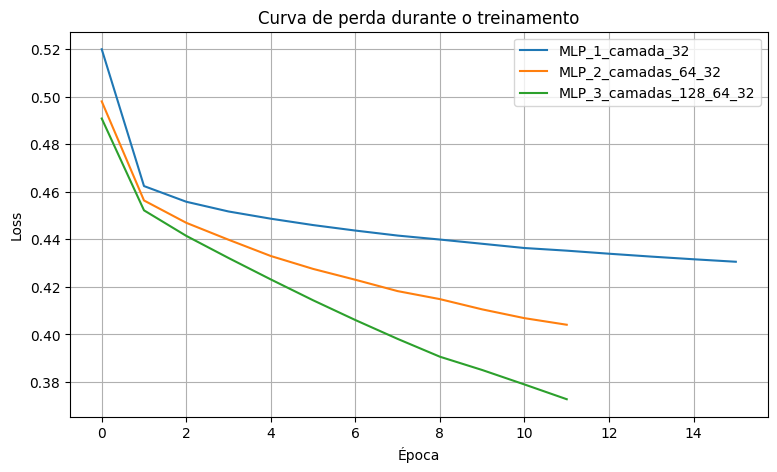

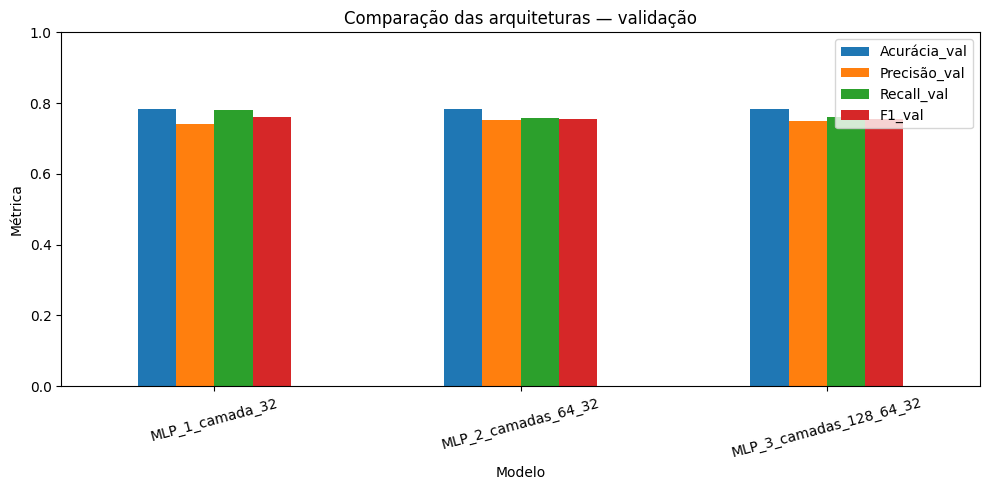

In [19]:
plt.figure(figsize=(9,5))
for nome, curva in historicos.items():
    plt.plot(curva, label=nome)
plt.title('Curva de perda durante o treinamento')
plt.xlabel('Época'); plt.ylabel('Loss'); plt.legend(); plt.grid(True); plt.show()

ax = comparacao.set_index('Modelo')[['Acurácia_val','Precisão_val','Recall_val','F1_val']].plot(kind='bar', figsize=(10,5))
ax.set_title('Comparação das arquiteturas — validação'); ax.set_ylabel('Métrica'); ax.set_ylim(0,1); plt.xticks(rotation=15); plt.tight_layout(); plt.show()

As curvas permitem observar como a perda dos modelos diminui durante o treinamento. A arquitetura com três camadas apresentou a menor perda de treinamento, porém isso não significou melhor desempenho na validação. Por esse motivo, a escolha do modelo considerou também as métricas de classificação, principalmente o F1-score.

## 8. Avaliação final no conjunto de teste

Modelo escolhido: MLP_1_camada_32
              precision    recall  f1-score   support

       Furto       0.81      0.79      0.80      9646
       Roubo       0.74      0.77      0.76      7609

    accuracy                           0.78     17255
   macro avg       0.78      0.78      0.78     17255
weighted avg       0.78      0.78      0.78     17255



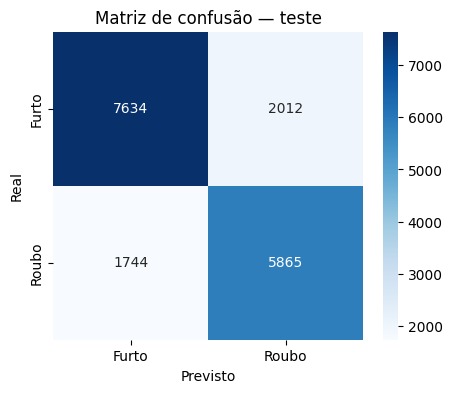

Acurácia: 0.782323964068386
Precisão: 0.7445728069061825
Recall: 0.7707977395189907
F1: 0.7574583494769469


In [20]:
pred_test = melhor_modelo.predict(X_test)
print('Modelo escolhido:', melhor_nome)
print(classification_report(y_test, pred_test, target_names=['Furto','Roubo'], zero_division=0))
cm = confusion_matrix(y_test, pred_test)
plt.figure(figsize=(5,4))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=['Furto','Roubo'], yticklabels=['Furto','Roubo'])
plt.xlabel('Previsto'); plt.ylabel('Real'); plt.title('Matriz de confusão — teste'); plt.show()
print('Acurácia:', accuracy_score(y_test, pred_test))
print('Precisão:', precision_score(y_test, pred_test, zero_division=0))
print('Recall:', recall_score(y_test, pred_test, zero_division=0))
print('F1:', f1_score(y_test, pred_test, zero_division=0))

O modelo selecionado foi avaliado utilizando dados que não participaram do treinamento nem da escolha da arquitetura. Foram obtidos 78,23% de acurácia e 75,75% de F1-score. A proximidade entre o resultado de validação e o de teste indica que o modelo manteve desempenho semelhante em dados não utilizados anteriormente.

## 9. Salvar modelo, comparação e CSV

In [21]:
import joblib
joblib.dump({'modelo': melhor_modelo, 'features_cat': features_cat, 'features_num': features_num}, '/content/modelo_mlp_roubo_furto.joblib')
comparacao.to_csv('/content/comparacao_mlp.csv', index=False, encoding='utf-8-sig')
print('Arquivos gerados: base_roubo_furto_sp_2025.csv, comparacao_mlp.csv, modelo_mlp_roubo_furto.joblib')
# Para baixar o CSV tratado, descomente a linha abaixo:
# files.download('/content/base_roubo_furto_sp_2025.csv')
# Para baixar o modelo:
# files.download('/content/modelo_mlp_roubo_furto.joblib')

Arquivos gerados: base_roubo_furto_sp_2025.csv, comparacao_mlp.csv, modelo_mlp_roubo_furto.joblib


A matriz de confusão apresenta a quantidade de classificações corretas e incorretas para cada classe. O modelo acertou 7.634 registros de furto e 5.865 de roubo. Também ocorreram classificações incorretas entre as duas categorias, demonstrando que o modelo ainda apresenta limitações na distinção de algumas ocorrências.

## 10. Interpretação e limitações

- A classe positiva foi codificada como `Roubo` (1) e `Furto` (0).
- As métricas dependem da base e do pré-processamento executado; não devem ser preenchidas manualmente.
- O conjunto de dados contém somente registros de subtração de celulares, não todas as ocorrências criminais.
- A base bruta pode conter linhas vinculadas ao mesmo boletim. A deduplicação segue a chave recomendada na metodologia da SSP-SP e elimina boletins com natureza conflitante.
- Variáveis como bairro e tipo de local podem apresentar alta cardinalidade ou valores ausentes.
- O resultado não é previsão de risco geográfico ou temporal e não substitui estatísticas oficiais nem decisão policial.
- Antes da entrega, registre as versões das bibliotecas, as decisões de limpeza e a interpretação dos resultados obtidos.

Após o treinamento, foram salvos o modelo selecionado, a base de dados tratada e a tabela de comparação das arquiteturas. Esses arquivos permitem reutilizar os resultados e integrar o modelo à aplicação web desenvolvida para o projeto.

In [23]:
from google.colab import files

files.download('/content/modelo_mlp_roubo_furto.joblib')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>